In [2]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset
!unzip brain-tumor-mri-dataset.zip

Streaming output truncated to the last 5000 lines.
  inflating: Training/glioma/Tr-gl_0712.jpg  
  inflating: Training/glioma/Tr-gl_0713.jpg  
  inflating: Training/glioma/Tr-gl_0714.jpg  
  inflating: Training/glioma/Tr-gl_0715.jpg  
  inflating: Training/glioma/Tr-gl_0716.jpg  
  inflating: Training/glioma/Tr-gl_0717.jpg  
  inflating: Training/glioma/Tr-gl_0718.jpg  
  inflating: Training/glioma/Tr-gl_0719.jpg  
  inflating: Training/glioma/Tr-gl_0720.jpg  
  inflating: Training/glioma/Tr-gl_0721.jpg  
  inflating: Training/glioma/Tr-gl_0722.jpg  
  inflating: Training/glioma/Tr-gl_0723.jpg  
  inflating: Training/glioma/Tr-gl_0724.jpg  
  inflating: Training/glioma/Tr-gl_0725.jpg  
  inflating: Training/glioma/Tr-gl_0726.jpg  
  inflating: Training/glioma/Tr-gl_0727.jpg  
  inflating: Training/glioma/Tr-gl_0728.jpg  
  inflating: Training/glioma/Tr-gl_0729.jpg  
  inflating: Training/glioma/Tr-gl_0730.jpg  
  inflating: Training/glioma/Tr-gl_0731.jpg  
  inflating: Training/glioma/

In [5]:
import tensorflow as tf
from tensorflow.keras import layers, Sequential

# Define constants
batch_size = 128
num_classes = 4
epochs = 60

# Load dataset without shuffling
trainset = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/Training",
    shuffle=True,
    batch_size=batch_size,
    image_size=(128, 128),
    seed=42
)

testset = tf.keras.preprocessing.image_dataset_from_directory(
    "/content/Testing",
    shuffle=False,
    batch_size=batch_size,
    image_size=(128, 128),
    seed=42
)

# Rescale pixel values
trainset = trainset.map(lambda x, y: (x / 255.0, y))
testset = testset.map(lambda x, y: (x / 255.0, y))

# Calculate dataset lengths
train_length = len(trainset)
val_length = int(0.1 * train_length)
train_length = train_length - val_length

# Split dataset
trainset = trainset.shuffle(buffer_size=train_length + val_length, seed=42)
train_ds = trainset.take(train_length)
val_ds = trainset.skip(train_length).take(val_length)

# Model
model = Sequential([
    layers.Conv2D(32, (3, 3), input_shape=(128, 128, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),

    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Display model summary
model.summary()

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(testset)
print('Test loss:', test_loss)
print('Test accuracy:', test_accuracy)

train_loss, train_accuracy = model.evaluate(train_ds)
print('Train loss:', train_loss)
print('Train accuracy:', train_accuracy)


Found 5712 files belonging to 4 classes.
Found 1311 files belonging to 4 classes.


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)                    │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_8                │ (None, 126, 126, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_9                │ (None, 61, 61, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_9 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_11 (Dropout)                 │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_10               │ (None, 28, 28, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_10 (MaxPooling2D)      │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_12 (Dropout)                 │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 12, 12, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_11               │ (None, 12, 12, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_11 (MaxPooling2D)      │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_13 (Dropout)                 │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 4608)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 512)                 │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_14 (Dropout)                 │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 2,604,100 (9.93 MB)

 Trainable params: 2,603,396 (9.93 MB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/60
41/41 ━━━━━━━━━━━━━━━━━━━━ 38s 519ms/step - accuracy: 0.5888 - loss: 2.4528 - val_accuracy: 0.2773 - val_loss: 5.1048
Epoch 2/60
41/41 ━━━━━━━━━━━━━━━━━━━━ 13s 211ms/step - accuracy: 0.8155 - loss: 0.4885 - val_accuracy: 0.2754 - val_loss: 6.2266
Epoch 3/60
41/41 ━━━━━━━━━━━━━━━━━━━━ 13s 212ms/step - accuracy: 0.8463 - loss: 0.4168 - val_accuracy: 0.3672 - val_loss: 6.5520
Epoch 4/60
41/41 ━━━━━━━━━━━━━━━━━━━━ 22s 236ms/step - accuracy: 0.8686 - loss: 0.3448 - val_accuracy: 0.3281 - val_loss: 8.8376
Epoch 5/60
41/41 ━━━━━━━━━━━━━━━━━━━━ 17s 321ms/step - accuracy: 0.8823 - loss: 0.2974 - val_accuracy: 0.3789 - val_loss: 8.0051
Epoch 6/60
41/41 ━━━━━━━━━━━━━━━━━━━━ 12s 195ms/step - accuracy: 0.9056 - loss: 0.2493 - val_accuracy: 0.3496 - val_loss: 11.5111
Epoch 7/60
41/41 ━━━━━━━━━━━━━━━━━━━━ 21s 215ms/step - accuracy: 0.9067 - loss: 0.2355 - val_accuracy: 0.4082 - val_loss: 8.7617
Epoch 8/60
41/41 ━━━━━━━━━━━━━━━━━━━━ 20s 180ms/step - accuracy: 0.9191 - loss: 0.2116 - val_acc

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
F1 Score: 0.9824700293022115
Precision: 0.9825601286087494
Recall: 0.9824561403508771

Classification Report:

              precision    recall  f1-score   support

     Class 0       0.98      0.96      0.97       300
     Class 1       0.95      0.97      0.96       306
     Class 2       1.00      1.00      1.00       405
     Class 3       0.99      0.99      0.99       300

    accuracy                           0.98      1311
   macro avg       0.98      0.98      0.98      1311
weighted avg       0.98      0.98      0.98      1311



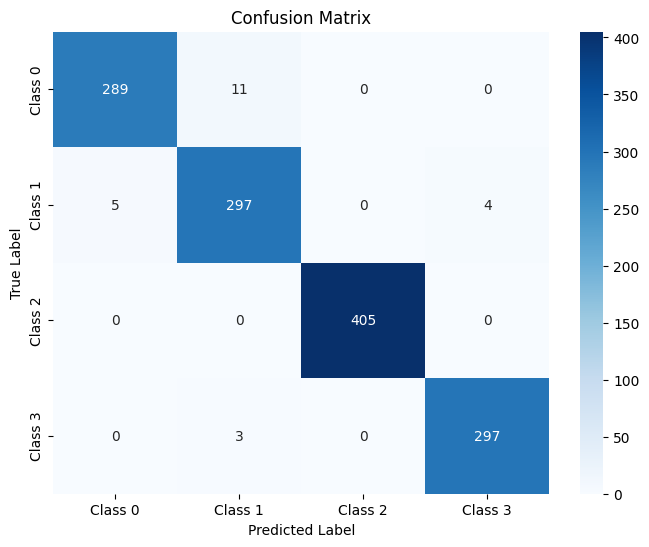

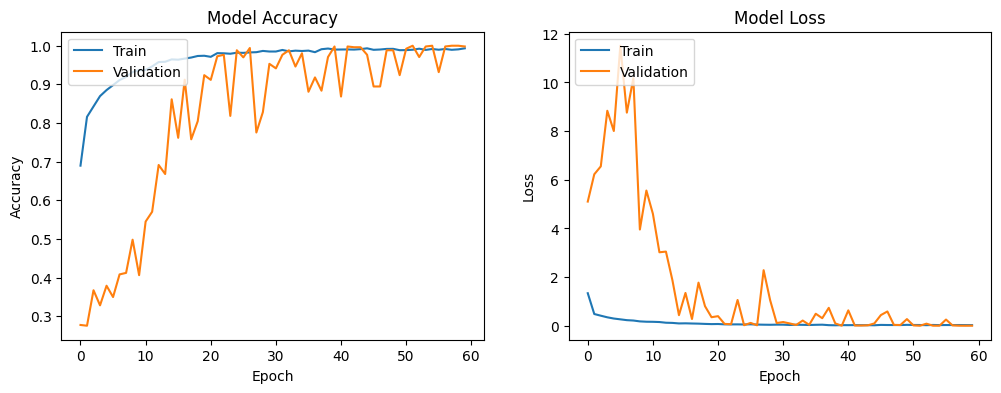

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score

# Generate predictions on the test set
y_true = []
y_pred = []

for images, labels in testset:
    predictions = model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Calculate precision, recall, and F1 score
f1 = f1_score(y_true, y_pred, average='weighted')
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')

print(f"F1 Score: {f1}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")

# Print classification report
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=[f'Class {i}' for i in range(num_classes)]))

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)

# Plot Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=[f'Class {i}' for i in range(num_classes)], yticklabels=[f'Class {i}' for i in range(num_classes)])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Plot training & validation accuracy values
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
F1 Score: 0.9824700293022115
Precision: 0.9825601286087494
Recall: 0.9824561403508771

Classification Report:

              precision    recall  f1-score   support

     Class 0       0.98      0.96      0.97       300
     Class 1       0.95      0.97      0.96       306
     Class 2       1.00      1.00      1.00       405
     Class 3       0.99      0.99      0.99       300

    accuracy                           0.98      1311
   macro avg       0.98      0.98      0.98      1311
weighted avg       0.98      0.98      0.98      1311



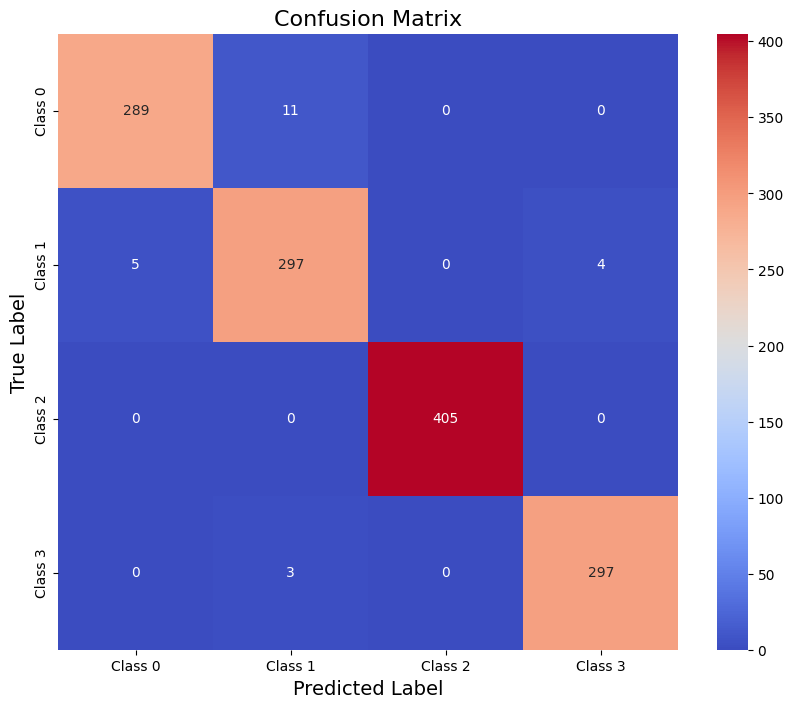

11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.9749 - loss: 0.1469 
Test loss: 0.09378816187381744
Test accuracy: 0.9824561476707458


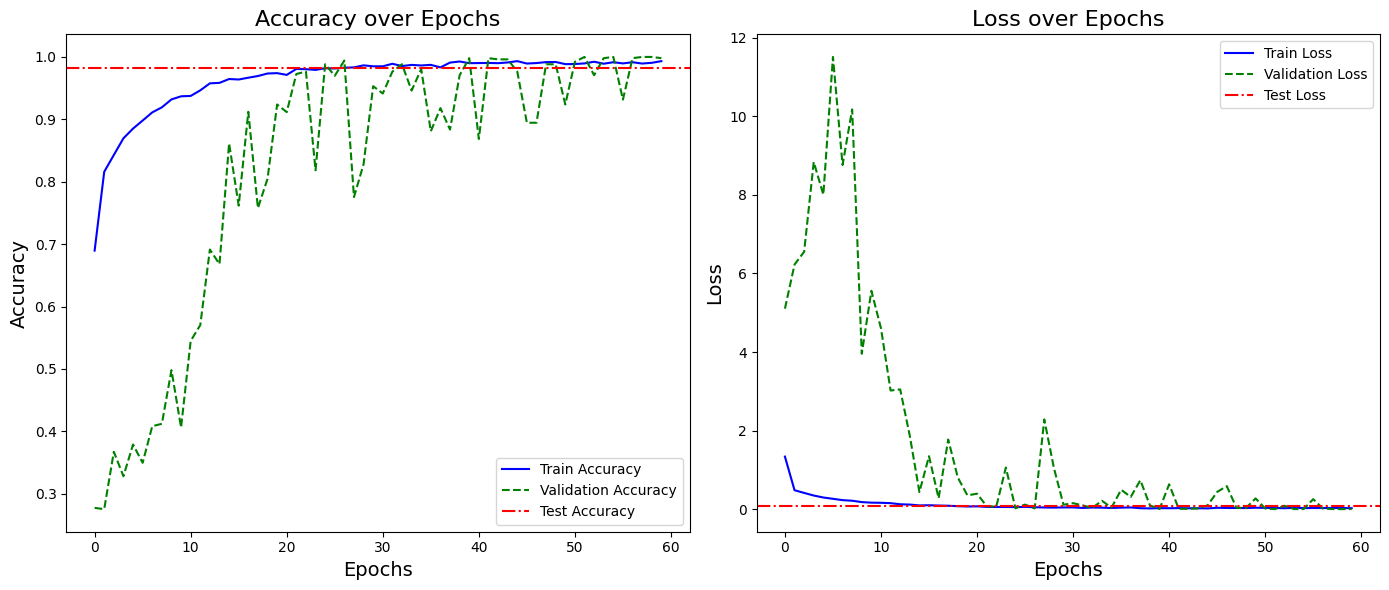

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score

# Generate predictions on the test set
y_true = []
y_pred = []

for images, labels in testset:
    predictions = model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Calculate precision, recall, and F1 score
f1 = f1_score(y_true, y_pred, average='weighted')
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')

print(f"F1 Score: {f1}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")

# Print classification report
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=[f'Class {i}' for i in range(num_classes)]))

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)

# Plot Confusion Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='coolwarm', xticklabels=[f'Class {i}' for i in range(num_classes)], yticklabels=[f'Class {i}' for i in range(num_classes)])
plt.title('Confusion Matrix', fontsize=16)
plt.xlabel('Predicted Label', fontsize=14)
plt.ylabel('True Label', fontsize=14)
plt.show()

# Plotting training, validation, and testing accuracy and loss together
# Since we only have training and validation metrics during training, we'll plot test metrics separately.

# Evaluate test set metrics
test_loss, test_accuracy = model.evaluate(testset)
print('Test loss:', test_loss)
print('Test accuracy:', test_accuracy)

# Plot training, validation, and test accuracy
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='blue', linestyle='-')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='green', linestyle='--')
plt.axhline(y=test_accuracy, color='red', linestyle='-.', label='Test Accuracy')
plt.title('Accuracy over Epochs', fontsize=16)
plt.xlabel('Epochs', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.legend(loc='lower right')

# Plot training, validation, and test loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='blue', linestyle='-')
plt.plot(history.history['val_loss'], label='Validation Loss', color='green', linestyle='--')
plt.axhline(y=test_loss, color='red', linestyle='-.', label='Test Loss')
plt.title('Loss over Epochs', fontsize=16)
plt.xlabel('Epochs', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()


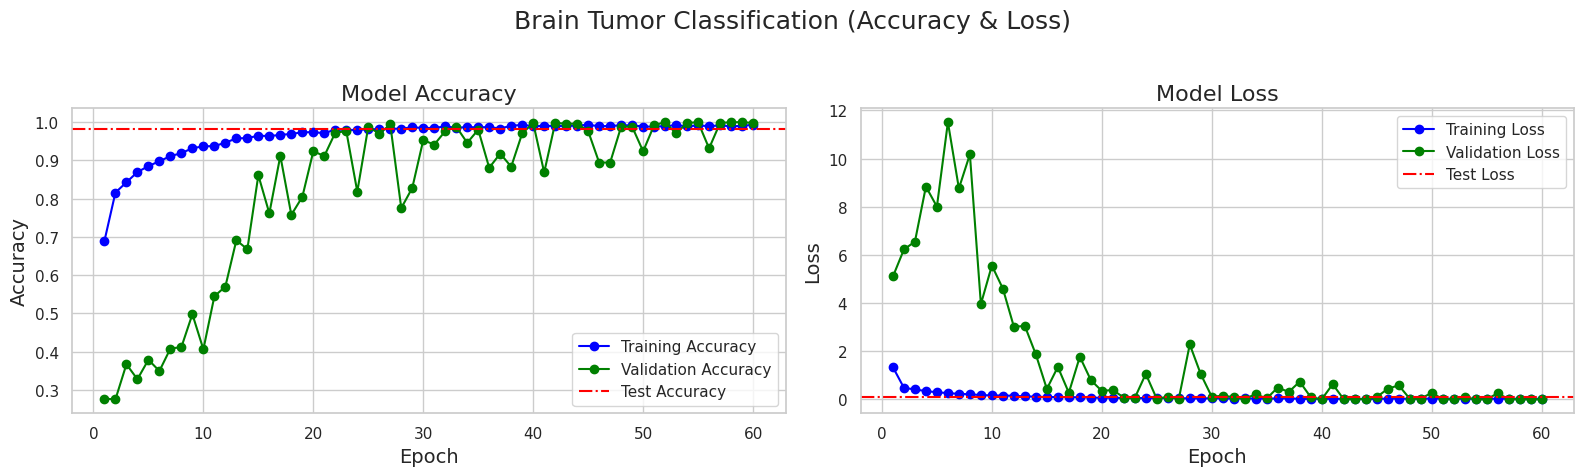

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set Seaborn style for the plots
sns.set(style="whitegrid")

# Assuming `history` is your training history object and `test_loss`, `test_accuracy` are obtained from model evaluation
epochs = range(1, len(history.history['accuracy']) + 1)

# Plotting Accuracy
plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, history.history['accuracy'], 'o-', label='Training Accuracy', color='blue')
plt.plot(epochs, history.history['val_accuracy'], 'o-', label='Validation Accuracy', color='green')
plt.axhline(y=test_accuracy, color='red', linestyle='-.', label='Test Accuracy')
plt.title('Model Accuracy', fontsize=16)
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Accuracy', fontsize=14)
plt.legend(loc='lower right')

# Plotting Loss
plt.subplot(1, 2, 2)
plt.plot(epochs, history.history['loss'], 'o-', label='Training Loss', color='blue')
plt.plot(epochs, history.history['val_loss'], 'o-', label='Validation Loss', color='green')
plt.axhline(y=test_loss, color='red', linestyle='-.', label='Test Loss')
plt.title('Model Loss', fontsize=16)
plt.xlabel('Epoch', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.legend(loc='upper right')

plt.suptitle('Brain Tumor Classification (Accuracy & Loss)', fontsize=18)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


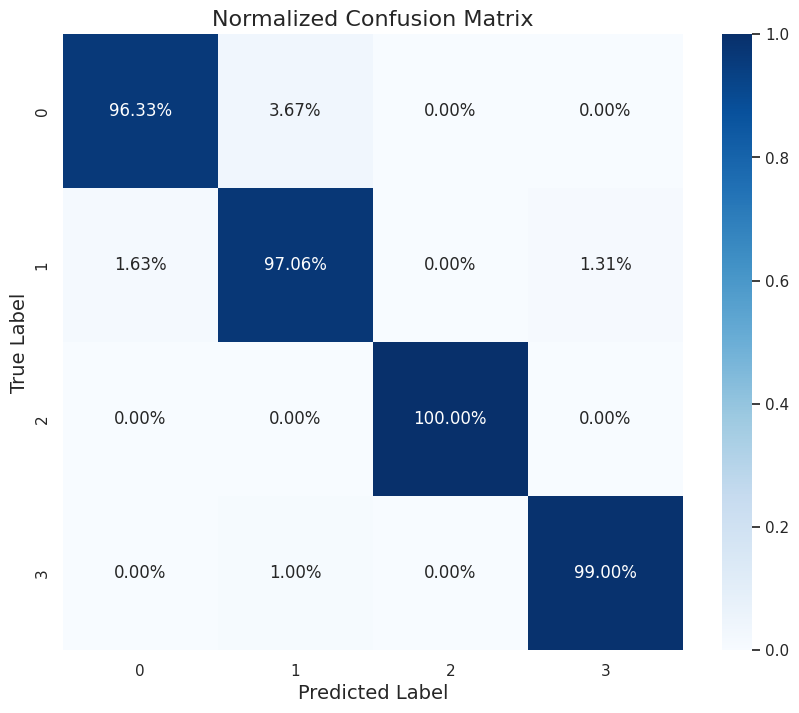

In [12]:
conf_matrix = confusion_matrix(y_true, y_pred)
conf_matrix_normalized = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix_normalized, annot=True, fmt=".2%", cmap='Blues')
plt.title('Normalized Confusion Matrix', fontsize=16)
plt.xlabel('Predicted Label', fontsize=14)
plt.ylabel('True Label', fontsize=14)
plt.show()

11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 213ms/step


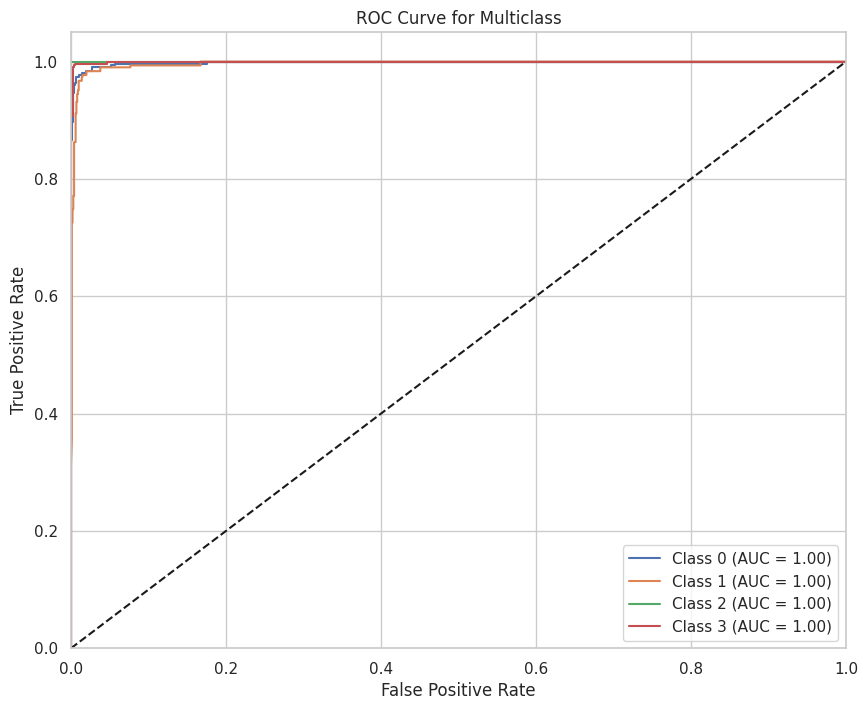

Overall AUC (One-vs-Rest): 1.00


In [16]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
import numpy as np

# Assuming testset is being evaluated
y_true = np.concatenate([y for x, y in testset], axis=0)
y_probs = model.predict(testset)  # Predicted probabilities for each class

# Binarize the labels for multiclass case
y_true_bin = label_binarize(y_true, classes=[0, 1, 2, 3])

# Compute AUC for each class
fpr = {}
tpr = {}
roc_auc = {}

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plotting the AUC-ROC curve for each class
plt.figure(figsize=(10, 8))
for i in range(num_classes):
    plt.plot(fpr[i], tpr[i], label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Multiclass')
plt.legend(loc="lower right")
plt.show()

# Overall AUC using the One-vs-Rest approach
overall_auc = roc_auc_score(y_true_bin, y_probs, multi_class='ovr')
print(f'Overall AUC (One-vs-Rest): {overall_auc:.2f}')
